In [4]:
import os
import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# Đường dẫn thư mục gốc dự án
PROJECT_ROOT = r"D:\TTNTNC\TicTacToe_AI"

# Thêm thư mục dự án vào Python Path
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# Chuyển thư mục làm việc về thư mục dự án
os.chdir(PROJECT_ROOT)

# Kiểm tra đường dẫn
print("Project Root:", PROJECT_ROOT)
print("Current Working Directory:", os.getcwd())

# Import các thành phần của dự án
from game.game_engine import GameEngine
from agents.minimax_agent import MinimaxAgent
from agents.alphabeta_agent import AlphaBetaAgent

# Cấu hình thí nghiệm
N_STATES = 20
SEARCH_DEPTH = 4

OUTPUT_DIR = os.path.join(
    PROJECT_ROOT,
    "results",
    "ablation_study"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("\nImport thành công!")
print("Output Directory:", OUTPUT_DIR)

Project Root: D:\TTNTNC\TicTacToe_AI
Current Working Directory: D:\TTNTNC\TicTacToe_AI

Import thành công!
Output Directory: D:\TTNTNC\TicTacToe_AI\results\ablation_study


In [5]:
rng = random.Random(2026)

test_positions = []

for state_id in range(N_STATES):

    game = GameEngine(
        board_size=4,
        win_length=4
    )

    game.reset()

    target_plies = rng.randint(3, 7)

    for _ in range(target_plies):

        if game.is_terminal():
            break

        legal_actions = game.legal_actions()

        if not legal_actions:
            break

        action = rng.choice(legal_actions)
        game.step(action)

    if not game.is_terminal():

        test_positions.append({
            "state_id": state_id + 1,
            "plies": target_plies,
            "game": game.clone()
        })

print("Số trạng thái được tạo:", len(test_positions))

assert len(test_positions) == N_STATES

Số trạng thái được tạo: 20


In [6]:
ablation_records = []

algorithms = {
    "Minimax": MinimaxAgent,
    "Alpha-Beta": AlphaBetaAgent
}

for algorithm_name, AgentClass in algorithms.items():

    print(f"\nĐang chạy {algorithm_name}...")

    agent = AgentClass(depth=SEARCH_DEPTH)

    for position in test_positions:

        game_copy = position["game"].clone()

        action = agent.choose_action(game_copy)

        stats = agent.get_search_stats()

        ablation_records.append({

            "Algorithm": algorithm_name,

            "State_ID": position["state_id"],

            "Plies": position["plies"],

            "Action": str(action),

            "Nodes_Visited": stats["nodes_visited"],

            "Nodes_Expanded": stats["nodes_expanded"],

            "Decision_Time": stats["decision_time"],

            "Nodes_Per_Second": stats["nodes_per_second"],

            "Pruned_Branches": stats.get(
                "pruned_branches", 0
            ),

            "Cutoffs": stats.get(
                "cutoffs", 0
            ),

            "Pruning_Rate": stats.get(
                "pruning_rate", 0
            )
        })

ablation_df = pd.DataFrame(ablation_records)

print("\nHoàn thành thí nghiệm!")
display(ablation_df.head(10))


Đang chạy Minimax...

Đang chạy Alpha-Beta...

Hoàn thành thí nghiệm!


,Algorithm,State_ID,Plies,Action,Nodes_Visited,Nodes_Expanded,Decision_Time,Nodes_Per_Second,Pruned_Branches,Cutoffs,Pruning_Rate
0,Minimax,1,3,"(0, 0)",19045,19045,2.241078,8498.142412,0,0,0.0
1,Minimax,2,3,"(1, 2)",19045,19045,2.243454,8489.142189,0,0,0.0
2,Minimax,3,7,"(0, 1)",3525,3525,0.410357,8590.083413,0,0,0.0
3,Minimax,4,6,"(3, 3)",4771,4771,0.447138,10670.091115,0,0,0.0
4,Minimax,5,3,"(3, 0)",19045,19045,1.486418,12812.682948,0,0,0.0
5,Minimax,6,6,"(0, 1)",5860,5860,0.426836,13728.929549,0,0,0.0
6,Minimax,7,6,"(3, 3)",5748,5748,0.423684,13566.718019,0,0,0.0
7,Minimax,8,5,"(1, 2)",9031,9031,0.692515,13040.870878,0,0,0.0
8,Minimax,9,7,"(2, 2)",3609,3609,0.259143,13926.657567,0,0,0.0
9,Minimax,10,6,"(3, 0)",5860,5860,0.444363,13187.404724,0,0,0.0


In [7]:
ablation_summary = (
    ablation_df
    .groupby("Algorithm")
    .agg(
        Total_States=("State_ID", "count"),

        Mean_Nodes=("Nodes_Visited", "mean"),

        Median_Nodes=("Nodes_Visited", "median"),

        Mean_Decision_Time=("Decision_Time", "mean"),

        Median_Decision_Time=("Decision_Time", "median"),

        Mean_Nodes_Per_Second=("Nodes_Per_Second", "mean"),

        Mean_Pruned_Branches=("Pruned_Branches", "mean"),

        Mean_Pruning_Rate=("Pruning_Rate", "mean")
    )
    .reset_index()
)

display(ablation_summary.round(4))

,Algorithm,Total_States,Mean_Nodes,Median_Nodes,Mean_Decision_Time,Median_Decision_Time,Mean_Nodes_Per_Second,Mean_Pruned_Branches,Mean_Pruning_Rate
0,Alpha-Beta,20,1320.5,1114.0,0.0949,0.0794,14428.4888,1282.95,52.9486
1,Minimax,20,9029.8,5748.0,0.7747,0.4298,12554.4328,0.00,0.0000


In [8]:
node_pivot = ablation_df.pivot(
    index="State_ID",
    columns="Algorithm",
    values="Nodes_Visited"
)

node_pivot["Node_Reduction_Percent"] = (
    (node_pivot["Minimax"] - node_pivot["Alpha-Beta"])
    / node_pivot["Minimax"] * 100
)

display(node_pivot.round(2))

print(
    "Mức giảm node trung bình:",
    round(node_pivot["Node_Reduction_Percent"].mean(), 2),
    "%"
)

Algorithm,Alpha-Beta,Minimax,Node_Reduction_Percent
State_ID,,,
1,1234,19045,93.52
2,1139,19045,94.02
3,576,3525,83.66
4,3083,4771,35.38
5,6351,19045,66.65
6,546,5860,90.68
7,865,5748,84.95
8,1256,9031,86.09
9,705,3609,80.47


Mức giảm node trung bình: 83.35 %


In [9]:
action_pivot = ablation_df.pivot(
    index="State_ID",
    columns="Algorithm",
    values="Action"
)

action_pivot["Same_Action"] = (
    action_pivot["Minimax"] == action_pivot["Alpha-Beta"]
)

display(action_pivot)

agreement = action_pivot["Same_Action"].mean() * 100

print(f"Tỷ lệ chọn cùng nước đi: {agreement:.2f}%")

Algorithm,Alpha-Beta,Minimax,Same_Action
State_ID,,,
1,"(0, 0)","(0, 0)",True
2,"(1, 2)","(1, 2)",True
3,"(0, 1)","(0, 1)",True
4,"(3, 3)","(3, 3)",True
5,"(3, 0)","(3, 0)",True
6,"(0, 1)","(0, 1)",True
7,"(3, 3)","(3, 3)",True
8,"(1, 2)","(1, 2)",True
9,"(2, 2)","(2, 2)",True


Tỷ lệ chọn cùng nước đi: 100.00%


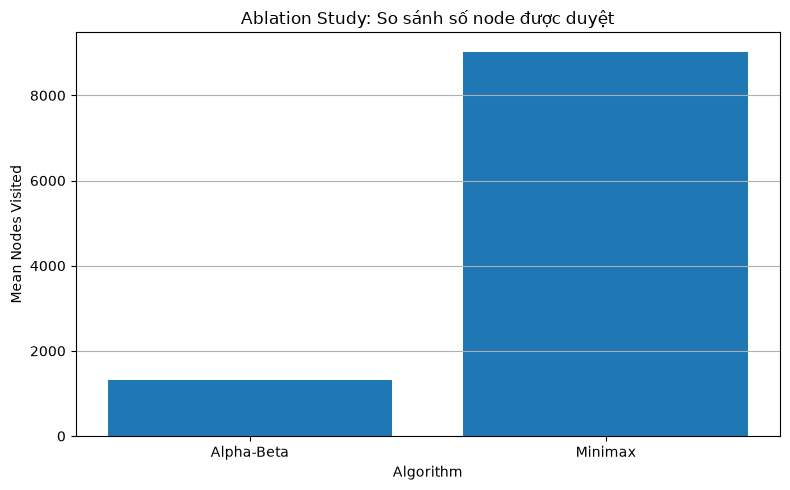

In [10]:
plt.figure(figsize=(8, 5))

plt.bar(
    ablation_summary["Algorithm"],
    ablation_summary["Mean_Nodes"]
)

plt.title("Ablation Study: So sánh số node được duyệt")
plt.xlabel("Algorithm")
plt.ylabel("Mean Nodes Visited")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

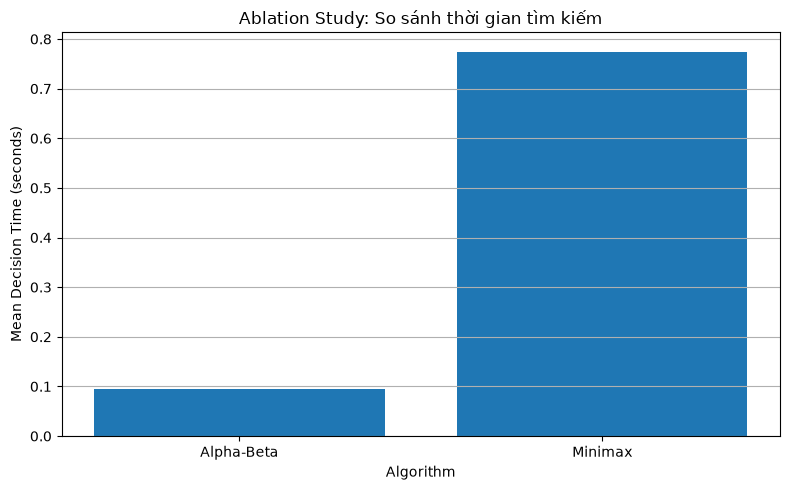

In [11]:
plt.figure(figsize=(8, 5))

plt.bar(
    ablation_summary["Algorithm"],
    ablation_summary["Mean_Decision_Time"]
)

plt.title("Ablation Study: So sánh thời gian tìm kiếm")
plt.xlabel("Algorithm")
plt.ylabel("Mean Decision Time (seconds)")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

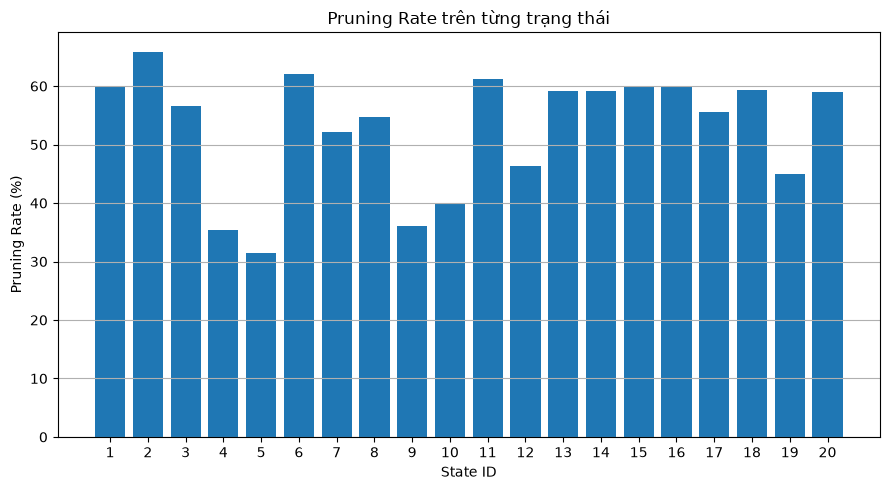

In [12]:
alpha_beta_data = ablation_df[
    ablation_df["Algorithm"] == "Alpha-Beta"
]

plt.figure(figsize=(9, 5))

plt.bar(
    alpha_beta_data["State_ID"].astype(str),
    alpha_beta_data["Pruning_Rate"]
)

plt.title("Pruning Rate trên từng trạng thái")
plt.xlabel("State ID")
plt.ylabel("Pruning Rate (%)")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [13]:
ablation_df.to_csv(
    os.path.join(OUTPUT_DIR, "ablation_raw_results.csv"),
    index=False,
    encoding="utf-8-sig"
)

ablation_summary.to_csv(
    os.path.join(OUTPUT_DIR, "ablation_summary.csv"),
    index=False,
    encoding="utf-8-sig"
)

excel_path = os.path.join(
    OUTPUT_DIR,
    "ablation_study_report.xlsx"
)

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:

    ablation_df.to_excel(
        writer,
        sheet_name="Raw Results",
        index=False
    )

    ablation_summary.to_excel(
        writer,
        sheet_name="Summary",
        index=False
    )

    node_pivot.to_excel(
        writer,
        sheet_name="Node Reduction"
    )

    action_pivot.to_excel(
        writer,
        sheet_name="Action Agreement"
    )

print("Đã lưu báo cáo tại:", excel_path)

Đã lưu báo cáo tại: D:\TTNTNC\TicTacToe_AI\results\ablation_study\ablation_study_report.xlsx


In [14]:
import os
import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = r"D:\TTNTNC\TicTacToe_AI"

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

os.chdir(PROJECT_ROOT)

from game.game_engine import GameEngine
from agents.mcts_agent import MCTSAgent
from agents.mcts_ablation import MCTSNoExpansionAgent

OUTPUT_DIR = os.path.join(
    PROJECT_ROOT,
    "results",
    "ablation_study"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Import MCTS Ablation thành công!")

Import MCTS Ablation thành công!


In [15]:
rng = random.Random(2026)

test_positions = []

for state_id in range(20):

    game = GameEngine(
        board_size=4,
        win_length=4
    )

    game.reset()

    target_plies = rng.randint(3, 7)

    for _ in range(target_plies):

        if game.is_terminal():
            break

        action = rng.choice(game.legal_actions())
        game.step(action)

    if not game.is_terminal():

        test_positions.append({
            "state_id": state_id + 1,
            "game": game.clone()
        })

assert len(test_positions) == 20

print("Đã tạo 20 trạng thái kiểm thử.")

Đã tạo 20 trạng thái kiểm thử.


In [16]:
BUDGET = 500

configs = {
    "Baseline": lambda seed: MCTSAgent(
        simulations=BUDGET,
        exploration=2 ** 0.5,
        seed=seed
    ),

    "No Exploration": lambda seed: MCTSAgent(
        simulations=BUDGET,
        exploration=0,
        seed=seed
    ),

    "No Expansion": lambda seed: MCTSNoExpansionAgent(
        simulations=BUDGET,
        exploration=2 ** 0.5,
        seed=seed
    )
}

records = []

for config_name, agent_factory in configs.items():

    print(f"\nĐang chạy: {config_name}")

    for position in test_positions:

        seed = 2026 + position["state_id"]

        agent = agent_factory(seed)

        game_copy = position["game"].clone()

        action = agent.choose_action(game_copy)

        stats = agent.get_search_stats()

        records.append({

            "Configuration": config_name,

            "State_ID": position["state_id"],

            "Action": str(action),

            "Decision_Time": stats["decision_time"],

            "Simulations_Completed":
                stats["simulations_completed"],

            "Nodes_Created":
                stats["nodes_created"],

            "Tree_Nodes_Visited":
                stats["tree_nodes_visited"],

            "Rollout_Steps":
                stats["rollout_steps"],

            "Simulations_Per_Second":
                stats["simulations_per_second"]
        })

mcts_ablation_df = pd.DataFrame(records)

display(mcts_ablation_df.head(10))

print("Hoàn thành!")


Đang chạy: Baseline

Đang chạy: No Exploration

Đang chạy: No Expansion


,Configuration,State_ID,Action,Decision_Time,Simulations_Completed,Nodes_Created,Tree_Nodes_Visited,Rollout_Steps,Simulations_Per_Second
0,Baseline,1,"(3, 0)",0.110567,500,501,1318,4591,4522.124494
1,Baseline,2,"(3, 0)",0.099460,500,501,1318,4670,5027.131428
2,Baseline,3,"(1, 0)",0.078667,500,493,1466,2414,6355.881033
3,Baseline,4,"(3, 3)",0.059478,500,305,1203,1492,8406.497890
4,Baseline,5,"(3, 0)",0.103302,500,501,1318,4303,4840.191400
5,Baseline,6,"(3, 0)",0.094784,500,501,1409,3001,5275.174187
6,Baseline,7,"(3, 3)",0.092367,500,500,1398,2540,5413.217996
7,Baseline,8,"(1, 0)",0.114279,500,501,1368,3710,4375.245561
8,Baseline,9,"(2, 0)",0.101168,500,501,1461,2488,4942.269352
9,Baseline,10,"(1, 2)",0.107014,500,501,1392,3446,4672.272771


Hoàn thành!


In [17]:
mcts_ablation_summary = (
    mcts_ablation_df
    .groupby("Configuration")
    .agg(
        Total_States=("State_ID", "count"),

        Mean_Decision_Time=("Decision_Time", "mean"),

        Mean_Simulations=("Simulations_Completed", "mean"),

        Mean_Nodes_Created=("Nodes_Created", "mean"),

        Mean_Tree_Nodes_Visited=("Tree_Nodes_Visited", "mean"),

        Mean_Rollout_Steps=("Rollout_Steps", "mean"),

        Mean_Simulations_Per_Second=(
            "Simulations_Per_Second", "mean"
        )
    )
    .reset_index()
)

display(mcts_ablation_summary.round(4))

,Configuration,Total_States,Mean_Decision_Time,Mean_Simulations,Mean_Nodes_Created,Mean_Tree_Nodes_Visited,Mean_Rollout_Steps,Mean_Simulations_Per_Second
0,Baseline,20,0.1023,500.0,490.0,1380.9,3219.80,5073.3918
1,No Expansion,20,0.7021,5325.0,1.0,0.0,45331.45,7922.8753
2,No Exploration,20,0.1220,500.0,156.3,4171.6,983.75,4532.8214


In [18]:
action_pivot = mcts_ablation_df.pivot(
    index="State_ID",
    columns="Configuration",
    values="Action"
)

agreement_records = []

for config in configs:

    same = (
        action_pivot[config] == action_pivot["Baseline"]
    ).sum()

    agreement_records.append({

        "Configuration": config,

        "Same_Action_Count": same,

        "Total_States": len(action_pivot),

        "Agreement_Percentage":
            same / len(action_pivot) * 100
    })

mcts_agreement_df = pd.DataFrame(agreement_records)

display(mcts_agreement_df.round(2))

,Configuration,Same_Action_Count,Total_States,Agreement_Percentage
0,Baseline,20,20,100.0
1,No Exploration,4,20,20.0
2,No Expansion,12,20,60.0


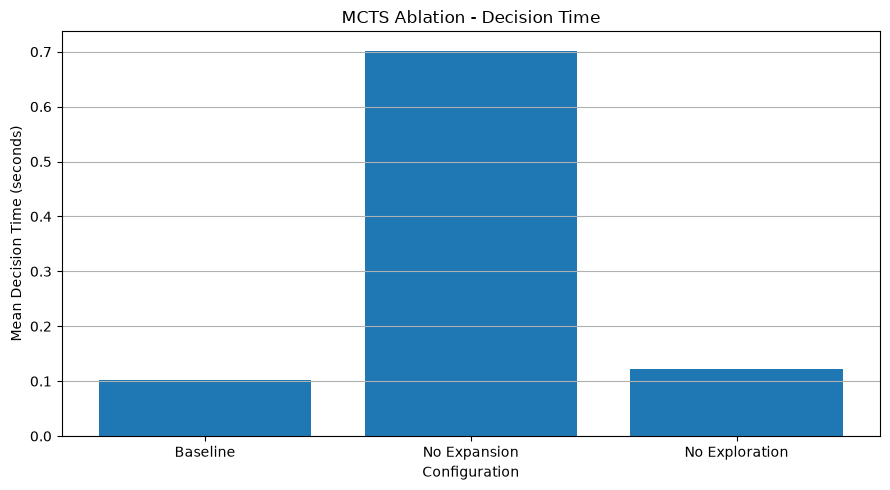

In [19]:
plt.figure(figsize=(9, 5))

plt.bar(
    mcts_ablation_summary["Configuration"],
    mcts_ablation_summary["Mean_Decision_Time"]
)

plt.title("MCTS Ablation - Decision Time")
plt.xlabel("Configuration")
plt.ylabel("Mean Decision Time (seconds)")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

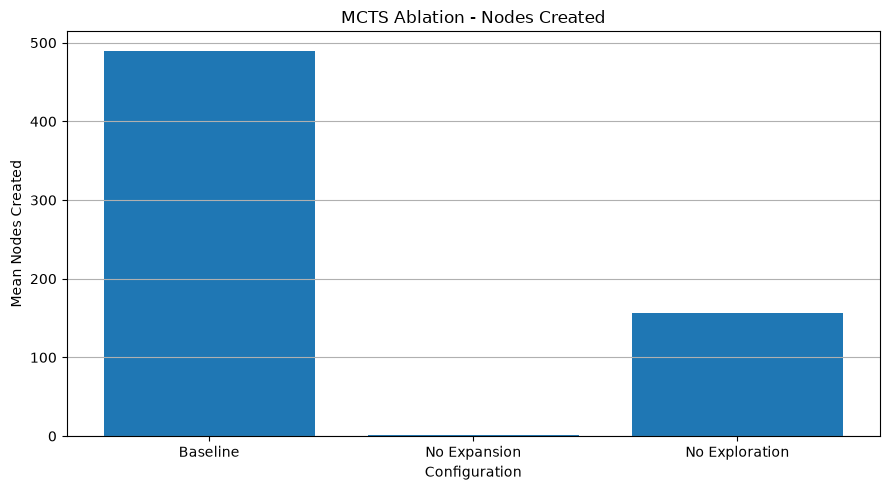

In [20]:
plt.figure(figsize=(9, 5))

plt.bar(
    mcts_ablation_summary["Configuration"],
    mcts_ablation_summary["Mean_Nodes_Created"]
)

plt.title("MCTS Ablation - Nodes Created")
plt.xlabel("Configuration")
plt.ylabel("Mean Nodes Created")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

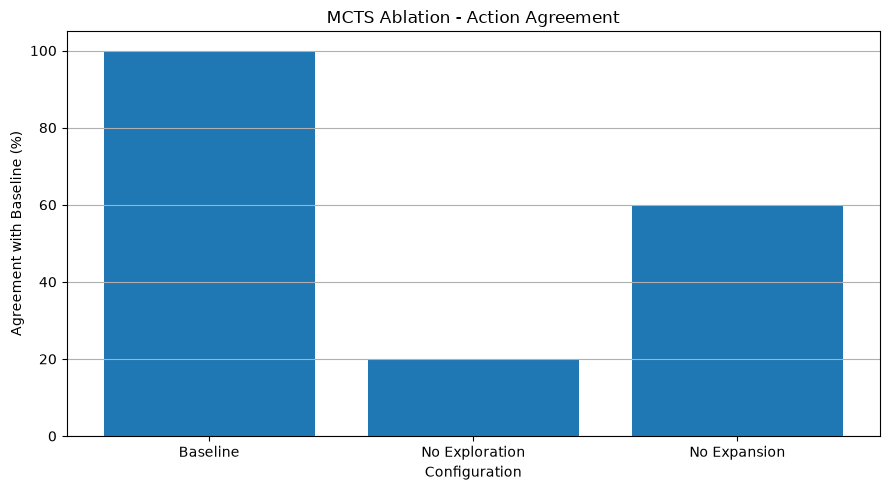

In [21]:
plt.figure(figsize=(9, 5))

plt.bar(
    mcts_agreement_df["Configuration"],
    mcts_agreement_df["Agreement_Percentage"]
)

plt.title("MCTS Ablation - Action Agreement")
plt.xlabel("Configuration")
plt.ylabel("Agreement with Baseline (%)")
plt.ylim(0, 105)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


In [22]:
mcts_ablation_df.to_csv(
    os.path.join(OUTPUT_DIR, "mcts_ablation_raw.csv"),
    index=False,
    encoding="utf-8-sig"
)

mcts_ablation_summary.to_csv(
    os.path.join(OUTPUT_DIR, "mcts_ablation_summary.csv"),
    index=False,
    encoding="utf-8-sig"
)

mcts_agreement_df.to_csv(
    os.path.join(OUTPUT_DIR, "mcts_ablation_agreement.csv"),
    index=False,
    encoding="utf-8-sig"
)

excel_path = os.path.join(
    OUTPUT_DIR,
    "mcts_ablation_report.xlsx"
)

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:

    mcts_ablation_df.to_excel(
        writer,
        sheet_name="Raw Results",
        index=False
    )

    mcts_ablation_summary.to_excel(
        writer,
        sheet_name="Summary",
        index=False
    )

    mcts_agreement_df.to_excel(
        writer,
        sheet_name="Action Agreement",
        index=False
    )

    action_pivot.to_excel(
        writer,
        sheet_name="Action Comparison"
    )

print("Đã xuất báo cáo:", excel_path)

Đã xuất báo cáo: D:\TTNTNC\TicTacToe_AI\results\ablation_study\mcts_ablation_report.xlsx
